# Notebook 1 — Dataset preparation and baseline model training

This notebook prepares the canonical SMS dataset, creates a deterministic stratified split, trains word-only and word+character TF-IDF LinearSVC models, evaluates them, and saves model bundles.

**Dataset limitation:** the canonical dataset has `text` and `label` columns but no timestamps. This is not a temporal evaluation.

## 1. Install and import libraries

In [1]:
!pip -q install pandas numpy scikit-learn scipy joblib matplotlib
import re, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

## 2. Upload dataset

In [2]:
DATA_PATH = "/content/sms_canonical.csv"
if not Path(DATA_PATH).exists():
    from google.colab import files
    uploaded = files.upload()
    csvs = [n for n in uploaded if n.lower().endswith(".csv")]
    if not csvs: raise FileNotFoundError("Upload sms_canonical.csv with text,label columns.")
    DATA_PATH = "/content/" + csvs[0]
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape, "Columns:", df.columns.tolist())
display(df.head())

Shape: (67008, 2) Columns: ['text', 'label']


,text,label
0,There be an update for your delivery CC 017281...,spam
1,watch your favorite english movies of all genr...,spam
2,aur what is the status for fms,ham
3,hi shalini sundi thank you for dialling speci...,spam
4,m tryin to understand too...,ham


## 3. Clean and split dataset

In [3]:
if not {"text","label"}.issubset(df.columns):
    raise ValueError("Expected columns: text,label")
df = df[["text","label"]].dropna().copy()
df["text"] = df["text"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.lower().str.strip()
df = df[(df.text != "") & df.label.isin(["ham","spam"])]
before = len(df)
df = df.drop_duplicates(subset=["text","label"]).reset_index(drop=True)
print("Rows:", len(df), "| duplicates removed:", before-len(df))
display(df.label.value_counts().to_frame("count"))
X_train, X_temp, y_train, y_temp = train_test_split(df.text, df.label, test_size=.30, random_state=42, stratify=df.label)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=.50, random_state=42, stratify=y_temp)
print("Train/validation/test:", len(X_train), len(X_val), len(X_test))

Rows: 66986 | duplicates removed: 22


,count
label,
ham,40828
spam,26158


Train/validation/test: 46890 10048 10048


## 4. Evaluation helper

In [4]:
def metrics(name, y_true, y_pred):
    return {"model":name, "accuracy":accuracy_score(y_true,y_pred),
            "spam_precision":precision_score(y_true,y_pred,pos_label="spam",zero_division=0),
            "spam_recall":recall_score(y_true,y_pred,pos_label="spam",zero_division=0),
            "spam_f1":f1_score(y_true,y_pred,pos_label="spam",zero_division=0),
            "macro_f1":f1_score(y_true,y_pred,average="macro",zero_division=0)}

## 5. Train word TF-IDF model

In [5]:
word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1,2), min_df=2, sublinear_tf=True)
Xtr_w = word_vec.fit_transform(X_train)
Xte_w = word_vec.transform(X_test)
word_model = LinearSVC(class_weight="balanced", random_state=42)
word_model.fit(Xtr_w, y_train)
pred_w = word_model.predict(Xte_w)
word_metrics = metrics("word_tfidf_linear_svm", y_test, pred_w)
print(word_metrics)
print(classification_report(y_test, pred_w, digits=4))

{'model': 'word_tfidf_linear_svm', 'accuracy': 0.9890525477707006, 'spam_precision': 0.9882232462877624, 'spam_recall': 0.9836901121304791, 'spam_f1': 0.9859514687100894, 'macro_f1': 0.9884917950105151}
              precision    recall  f1-score   support

         ham     0.9896    0.9925    0.9910      6124
        spam     0.9882    0.9837    0.9860      3924

    accuracy                         0.9891     10048
   macro avg     0.9889    0.9881    0.9885     10048
weighted avg     0.9891    0.9891    0.9890     10048



## 6. Train word + character model

In [6]:
char_vec = TfidfVectorizer(analyzer="char", ngram_range=(3,5), min_df=2, sublinear_tf=True)
Xtr_c = char_vec.fit_transform(X_train)
Xte_c = char_vec.transform(X_test)
Xtr_wc = hstack([Xtr_w, Xtr_c]).tocsr()
Xte_wc = hstack([Xte_w, Xte_c]).tocsr()
word_char_model = LinearSVC(class_weight="balanced", random_state=42)
word_char_model.fit(Xtr_wc, y_train)
pred_wc = word_char_model.predict(Xte_wc)
word_char_metrics = metrics("word_char_tfidf_linear_svm", y_test, pred_wc)
print(word_char_metrics)
print(classification_report(y_test, pred_wc, digits=4))

{'model': 'word_char_tfidf_linear_svm', 'accuracy': 0.9932324840764332, 'spam_precision': 0.9948665297741273, 'spam_recall': 0.9877675840978594, 'spam_f1': 0.991304347826087, 'macro_f1': 0.9928825421111536}
              precision    recall  f1-score   support

         ham     0.9922    0.9967    0.9945      6124
        spam     0.9949    0.9878    0.9913      3924

    accuracy                         0.9932     10048
   macro avg     0.9935    0.9923    0.9929     10048
weighted avg     0.9932    0.9932    0.9932     10048



## 7. Compare and save artifacts

,model,accuracy,spam_precision,spam_recall,spam_f1,macro_f1
0,word_tfidf_linear_svm,0.989053,0.988223,0.983690,0.985951,0.988492
1,word_char_tfidf_linear_svm,0.993232,0.994867,0.987768,0.991304,0.992883


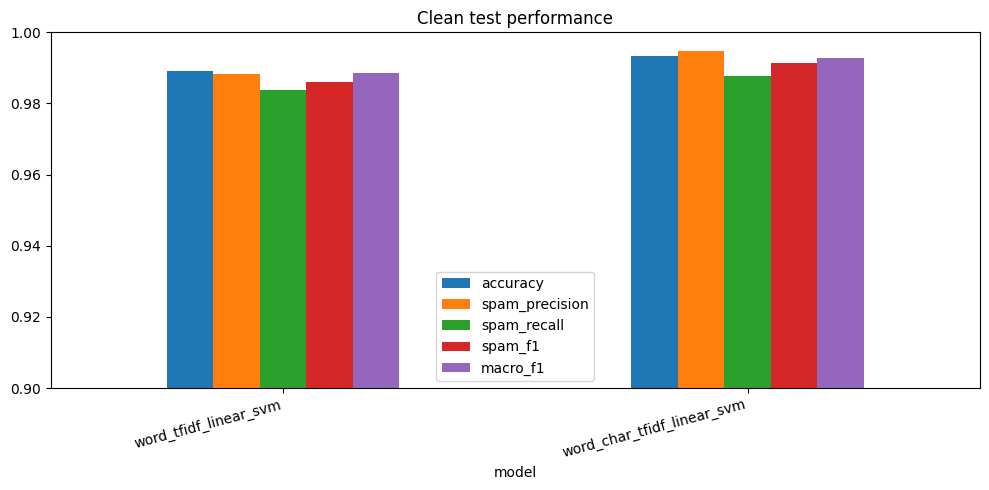

Saved files: [PosixPath('/content/sms_spam_outputs/clean_test_metrics.csv'), PosixPath('/content/sms_spam_outputs/word_char_model.joblib'), PosixPath('/content/sms_spam_outputs/word_only_model.joblib')]


In [7]:
results = pd.DataFrame([word_metrics, word_char_metrics])
display(results)
results.set_index("model")[["accuracy","spam_precision","spam_recall","spam_f1","macro_f1"]].plot(kind="bar", ylim=(.90,1), figsize=(10,5))
plt.title("Clean test performance"); plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()
OUT = Path("/content/sms_spam_outputs"); OUT.mkdir(exist_ok=True)
joblib.dump({"word_vectorizer":word_vec,"classifier":word_model,"model_name":"word_only"}, OUT/"word_only_model.joblib")
joblib.dump({"word_vectorizer":word_vec,"char_vectorizer":char_vec,"classifier":word_char_model,"model_name":"word_char"}, OUT/"word_char_model.joblib")
results.to_csv(OUT/"clean_test_metrics.csv", index=False)
print("Saved files:", list(OUT.iterdir()))

## Interpretation and reporting

Previously recorded project results were about 98.75% accuracy for word-only and 99.24% for word+character. Compare the newly generated values rather than hard-coding those values. Exact reproduction requires matching the original scripts' cleaning rules and hyperparameters.